In [1]:
%pip install tensorflow matplotlib numpy

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path
from tensorflow.keras.applications import EfficientNetB0

dataset_path = Path(
    r"C:\Users\prama\Downloads\project\survillenceimagesexpanded"
)

print("TensorFlow version:", tf.__version__)
print("Dataset exists:", dataset_path.exists())

if not dataset_path.exists():
    raise FileNotFoundError(
        f"Dataset folder not found: {dataset_path}"
    )

TensorFlow version: 2.21.0
Dataset exists: True


In [4]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    validation_split=0.3,
    subset="training",
    seed=123,
    image_size=(224, 224),
    batch_size=16,
    label_mode="int"
)

class_names = train_ds.class_names

print("Classes:", class_names)
print("Number of classes:", len(class_names))

if len(class_names) != 3:
    raise ValueError(
        f"Expected 3 class folders, but found: {class_names}"
    )

Found 1049 files belonging to 3 classes.
Using 735 files for training.


Classes: ['dangerimagesexpanded', 'isolatedimagesexpanded', 'safeimagesexpanded']
Number of classes: 3


In [6]:
val_test_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    validation_split=0.3,
    subset="validation",
    seed=123,
    image_size=(224, 224),
    batch_size=16,
    label_mode="int"
)

# Split the remaining data into validation and test batches
total_batches = len(val_test_ds)
val_size = total_batches // 2

if val_size == 0 or val_size == total_batches:
    raise ValueError(
        "Not enough batches to create separate validation and test sets."
    )

val_ds = val_test_ds.take(val_size)
test_ds = val_test_ds.skip(val_size)

print("Training batches:", len(train_ds))
print("Validation batches:", len(val_ds))
print("Testing batches:", len(test_ds))

Found 1049 files belonging to 3 classes.
Using 314 files for validation.


Training batches: 46
Validation batches: 10
Testing batches: 10


In [7]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

print("Dataset loading optimized.")

Dataset loading optimized.


In [8]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1),
    tf.keras.layers.RandomBrightness(0.2),
])

print("Data augmentation configured.")

Data augmentation configured.


In [9]:
base_model = EfficientNetB0(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

# Freeze the pretrained layers for initial training
base_model.trainable = False

print("EfficientNetB0 loaded successfully.")
print("Pretrained layers frozen:", not base_model.trainable)

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 6s 0us/step
EfficientNetB0 loaded successfully.
Pretrained layers frozen: True


In [10]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(224, 224, 3)),
    data_augmentation,
    base_model,
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(3, activation="softmax")
])

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 3)              │         3,843 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,053,414 (15.46 MB)

 Trainable params: 3,843 (15.01 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [11]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0003
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully.")

Model compiled successfully.


In [12]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20
)

Epoch 1/20


C:\Users\prama\AppData\Roaming\Python\Python313\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


46/46 ━━━━━━━━━━━━━━━━━━━━ 24s 369ms/step - accuracy: 0.3918 - loss: 1.1005 - val_accuracy: 0.4375 - val_loss: 1.0380
Epoch 2/20
46/46 ━━━━━━━━━━━━━━━━━━━━ 15s 314ms/step - accuracy: 0.5415 - loss: 0.9166 - val_accuracy: 0.6062 - val_loss: 0.8465
Epoch 3/20
46/46 ━━━━━━━━━━━━━━━━━━━━ 14s 304ms/step - accuracy: 0.6272 - loss: 0.8161 - val_accuracy: 0.7063 - val_loss: 0.7342
Epoch 4/20
46/46 ━━━━━━━━━━━━━━━━━━━━ 13s 289ms/step - accuracy: 0.6558 - loss: 0.7498 - val_accuracy: 0.7937 - val_loss: 0.6604
Epoch 5/20
46/46 ━━━━━━━━━━━━━━━━━━━━ 13s 289ms/step - accuracy: 0.6952 - loss: 0.7065 - val_accuracy: 0.7875 - val_loss: 0.6204
Epoch 6/20
46/46 ━━━━━━━━━━━━━━━━━━━━ 14s 307ms/step - accuracy: 0.7129 - loss: 0.6621 - val_accuracy: 0.8000 - val_loss: 0.6070
Epoch 7/20
46/46 ━━━━━━━━━━━━━━━━━━━━ 14s 309ms/step - accuracy: 0.7456 - loss: 0.6091 - val_accuracy: 0.8250 - val_loss: 0.5343
Epoch 8/20
46/46 ━━━━━━━━━━━━━━━━━━━━ 15s 319ms/step - accuracy: 0.7878 - loss: 0.5668 - val_accuracy: 0.800

In [13]:
initial_test_loss, initial_test_acc = model.evaluate(test_ds)

print("Initial Test Loss:", initial_test_loss)
print(f"Initial Test Accuracy: {initial_test_acc * 100:.2f}%")

10/10 ━━━━━━━━━━━━━━━━━━━━ 3s 230ms/step - accuracy: 0.8377 - loss: 0.4459
Initial Test Loss: 0.44591933488845825
Initial Test Accuracy: 83.77%


In [14]:
model.save("efficientnetb0_expanded_dataset_initial.keras")

print("Initial EfficientNetB0 model saved successfully!")

Initial EfficientNetB0 model saved successfully!


In [15]:
base_model.trainable = True

# Freeze all but the last 30 layers
for layer in base_model.layers[:-30]:
    layer.trainable = False

# Keep Batch Normalization layers frozen for stability
for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-5
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Fine-tuning configured.")

Fine-tuning configured.


In [16]:
history_finetune = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10
)

Epoch 1/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 27s 400ms/step - accuracy: 0.8449 - loss: 0.4313 - val_accuracy: 0.8500 - val_loss: 0.4447
Epoch 2/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 15s 330ms/step - accuracy: 0.8639 - loss: 0.4029 - val_accuracy: 0.8500 - val_loss: 0.4366
Epoch 3/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 15s 325ms/step - accuracy: 0.8463 - loss: 0.4077 - val_accuracy: 0.8625 - val_loss: 0.4525
Epoch 4/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 15s 328ms/step - accuracy: 0.8531 - loss: 0.4118 - val_accuracy: 0.8813 - val_loss: 0.4092
Epoch 5/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 15s 326ms/step - accuracy: 0.8435 - loss: 0.3915 - val_accuracy: 0.8500 - val_loss: 0.4410
Epoch 6/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 15s 326ms/step - accuracy: 0.8667 - loss: 0.3804 - val_accuracy: 0.8687 - val_loss: 0.3789
Epoch 7/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 15s 328ms/step - accuracy: 0.8531 - loss: 0.3755 - val_accuracy: 0.8500 - val_loss: 0.4377
Epoch 8/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 15s 327ms/step - accuracy: 0.8612 - loss: 0.3567 - val_accu

In [17]:
finetuned_test_loss, finetuned_test_acc = model.evaluate(test_ds)

print("Fine-tuned Test Loss:", finetuned_test_loss)
print(f"Fine-tuned Test Accuracy: {finetuned_test_acc * 100:.2f}%")

10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 226ms/step - accuracy: 0.8506 - loss: 0.4542
Fine-tuned Test Loss: 0.45423969626426697
Fine-tuned Test Accuracy: 85.06%


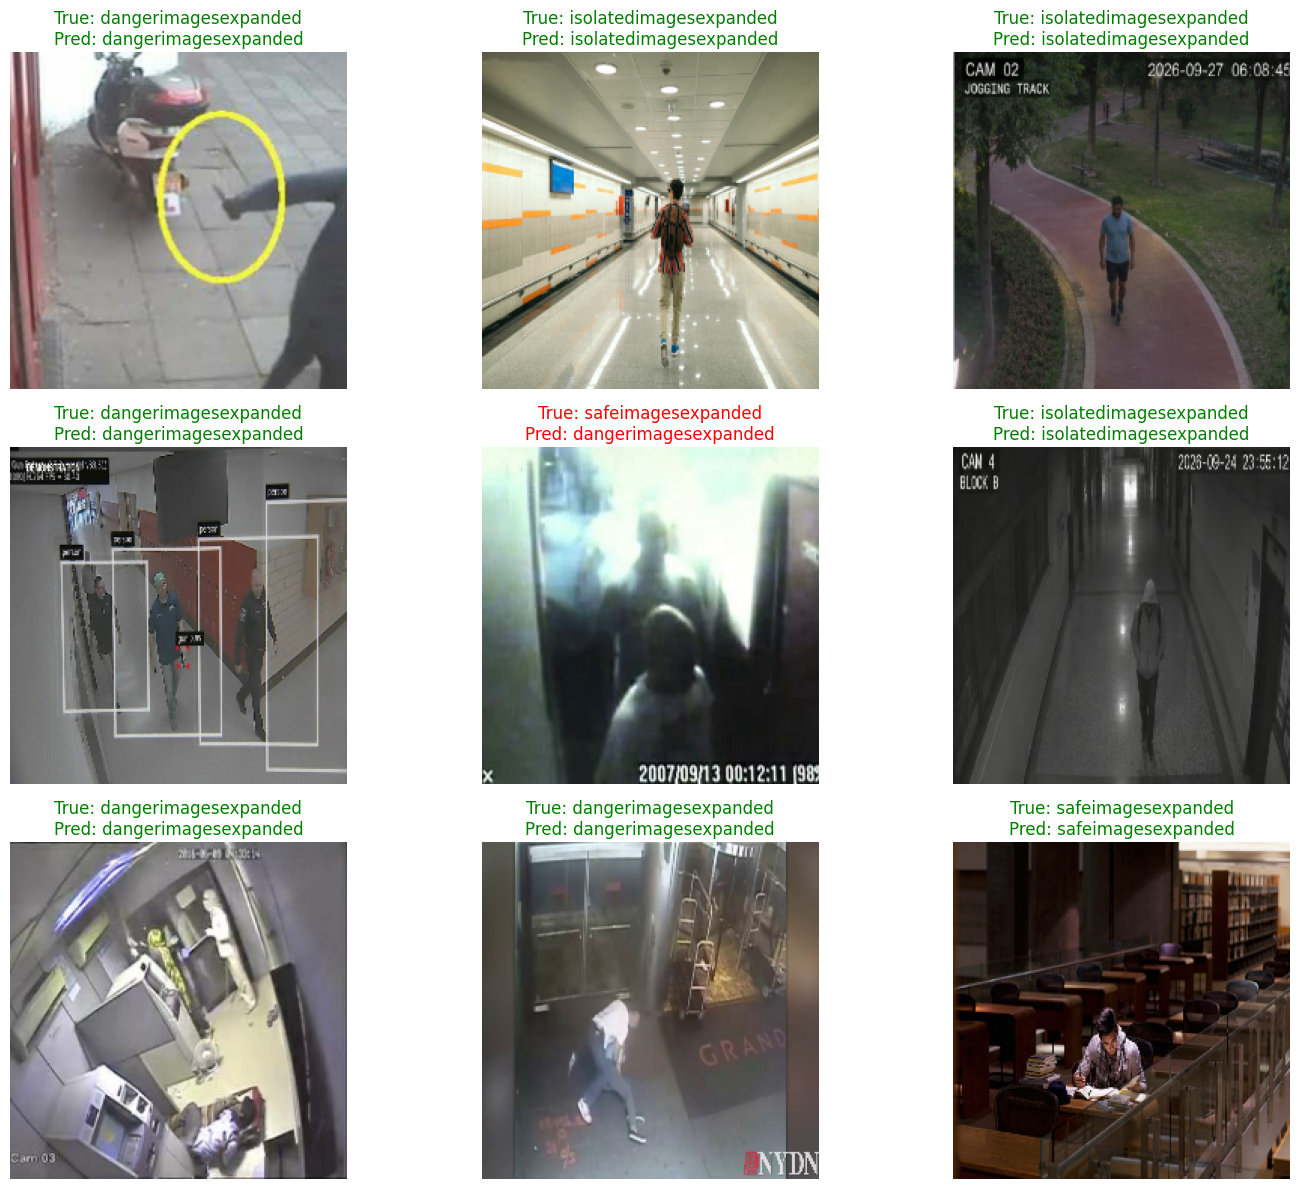

In [18]:
for images, labels in test_ds.take(1):
    predictions = model.predict(images, verbose=0)
    predicted_labels = np.argmax(predictions, axis=1)

    num_images = min(9, len(images))

    plt.figure(figsize=(15, 12))

    for i in range(num_images):
        plt.subplot(3, 3, i + 1)

        plt.imshow(images[i].numpy().astype("uint8"))

        true_label = class_names[int(labels[i].numpy())]
        pred_label = class_names[int(predicted_labels[i])]

        color = "green" if true_label == pred_label else "red"

        plt.title(
            f"True: {true_label}\nPred: {pred_label}",
            color=color
        )
        plt.axis("off")

    plt.tight_layout()
    plt.show()

In [19]:
model.save("efficientnetb0_expanded_dataset_finetuned.keras")

print("Fine-tuned EfficientNetB0 model saved successfully!")

print("\nFinal Results")
print(f"Initial test accuracy: {initial_test_acc * 100:.2f}%")
print(f"Fine-tuned test accuracy: {finetuned_test_acc * 100:.2f}%")

Fine-tuned EfficientNetB0 model saved successfully!

Final Results
Initial test accuracy: 83.77%
Fine-tuned test accuracy: 85.06%
